# Phase 4: Classical Regression Benchmarking
### AeroRUL — Remaining Useful Life Estimation for Turbofan Engines

This notebook implements the classical machine-learning benchmark for RUL estimation on NASA C-MAPSS datasets (FD001–FD004).

#### Key Principles:
1. **Classical ML Only**: Baselines, Linear/Ridge Regression, Random Forest, XGBoost, LightGBM.
2. **Leakage-Safe**: Engine-level split preserved; scalers fitted on training data only.
3. **No Target Leakage**: RUL and metadata strictly excluded from predictors.
4. **C-MAPSS Evaluation**: Row-level metrics, engine-macro metrics, endpoint metrics, and the official NASA asymmetric score.
5. **Ablation & Sensitivity**: RUL-cap sensitivity, window ablation, deduplication sensitivity.
6. **Official Test Set Reserved**: Test set untouched; evaluation performed on Phase 2 validation split.


In [1]:
import sys
import warnings
from pathlib import Path

# Ensure project root is on sys.path
_cwd = Path.cwd()
PROJECT_ROOT = _cwd.parent if _cwd.name == 'notebooks' else _cwd
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    AVAILABLE_SUBSETS,
    FIGURE_DPI,
    FIGURE_FORMAT,
    PHASE3_DATA_DIR,
    REPORTS_DIR,
    TARGET_COLUMN,
    RUL_CLIP_VALUES,
)
from src.features import get_feature_columns, _parse_feature_name
from src.metrics import (
    mae, rmse, r2_score, mean_signed_error,
    nasa_score, nasa_score_per_engine,
    engine_macro_metrics, extract_endpoints, endpoint_metrics,
    rul_range_error_analysis, evaluate_model, assign_rul_range,
)
from src.run_phase4_benchmark import (
    load_phase3_data,
    load_approved_features,
    data_preflight,
    prepare_clean_features,
    ALL_MODEL_CONFIGS,
    train_and_predict,
    create_predictions_df,
    detect_exact_duplicates_train,
    select_window_features,
    RUL_CAPS,
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8' if 'seaborn-v0_8' in plt.style.available else 'default')
%matplotlib inline

print('AeroRUL Phase 4 benchmarking modules loaded successfully.')


AeroRUL Phase 4 benchmarking modules loaded successfully.


## 1. Data Loading & Strict Data Preflight Check

Verify that data satisfies all Phase 4 integrity criteria:
- Valid RUL target (nonnegative, no failure_cycle leakage)
- No target/metadata in predictor matrix
- Only approved Phase 3.1 features used
- Strict engine separation between train and validation


In [2]:
subset = 'FD001'
train_df, val_df = load_phase3_data(subset)
approved = load_approved_features(subset)

preflight = data_preflight(train_df, val_df, approved, subset)
print(f"Subset: {subset}")
print(f"Preflight Passed: {preflight['passed']}")
print(f"Approved Features: {preflight['n_approved']}, Usable in Data: {preflight['n_usable']}")
print(f"Train: {preflight['n_train_rows']} rows, {preflight['n_train_engines']} engines")
print(f"Validation: {preflight['n_val_rows']} rows, {preflight['n_val_engines']} engines")
print(f"Issues detected: {preflight['issues']}")


Subset: FD001
Preflight Passed: True
Approved Features: 670, Usable in Data: 670
Train: 10641 rows, 80 engines
Validation: 2590 rows, 20 engines
Issues detected: []


## 2. Model A — Trivial Baseline (Dummy Regressor)

Predict median training RUL unconditionally. This establishes whether degradation features provide genuine predictive value over an uninformed baseline.


In [3]:
usable_features = preflight['usable_features']
X_train, X_val, y_train, y_val = prepare_clean_features(train_df, val_df, usable_features)

# Fit Baseline
dummy_cfg = ALL_MODEL_CONFIGS['DummyBaseline']
model, scaler, preds_raw, runtime = train_and_predict('DummyBaseline', dummy_cfg, X_train, y_train, X_val)
preds_dummy_df = create_predictions_df(val_df, preds_raw, 'DummyBaseline', subset)

metrics_dummy = evaluate_model(preds_dummy_df)
print(f"Dummy Baseline (Median) on {subset}:")
print(f"  Row MAE:          {metrics_dummy['row_mae']:.2f} cycles")
print(f"  Row RMSE:         {metrics_dummy['row_rmse']:.2f} cycles")
print(f"  Endpoint MAE:     {metrics_dummy['endpoint_mae']:.2f} cycles")
print(f"  Endpoint NASA:    {metrics_dummy['endpoint_nasa_score']:.1f}")


Dummy Baseline (Median) on FD001:
  Row MAE:          39.05 cycles
  Row RMSE:         47.57 cycles
  Endpoint MAE:     66.00 cycles
  Endpoint NASA:    14681.9


## 3. Primary Model Benchmark (FD001)

Evaluate all model families on identical approved features:
- Linear Regression (Standardized, fitted on train only)
- Ridge Regression (alpha=1.0)
- Random Forest (300 trees, sqrt features, min_samples_leaf=5)
- XGBoost (hist gradient boosting)
- LightGBM (leaf-wise gradient boosting)


In [4]:
benchmark_results = [metrics_dummy]
benchmark_results[0]['model'] = 'DummyBaseline'
predictions_dict = {'DummyBaseline': preds_dummy_df}

for model_name, cfg in ALL_MODEL_CONFIGS.items():
    if model_name == 'DummyBaseline':
        continue
    print(f"Training {model_name}...", end=' ')
    model, scaler, preds_raw, rt = train_and_predict(model_name, cfg, X_train, y_train, X_val)
    preds_df = create_predictions_df(val_df, preds_raw, model_name, subset)
    metrics = evaluate_model(preds_df)
    metrics['model'] = model_name
    metrics['runtime'] = rt
    benchmark_results.append(metrics)
    predictions_dict[model_name] = preds_df
    print(f"Row MAE: {metrics['row_mae']:.2f}, EP MAE: {metrics['endpoint_mae']:.2f}, NASA: {metrics['endpoint_nasa_score']:.1f} ({rt:.1f}s)")

# Format summary table
bm_df = pd.DataFrame(benchmark_results)[
    ['model', 'row_mae', 'row_rmse', 'row_r2', 'endpoint_mae', 'endpoint_rmse', 'endpoint_nasa_score', 'runtime']
].sort_values('endpoint_mae')
display(bm_df)


Training LinearRegression... 

Row MAE: 14.32, EP MAE: 2.77, NASA: 10.1 (1.0s)
Training RidgeRegression... 

Row MAE: 14.26, EP MAE: 2.62, NASA: 10.4 (0.2s)
Training RandomForest... 

Row MAE: 10.15, EP MAE: 2.65, NASA: 6.3 (26.8s)
Training XGBoost... 

Row MAE: 10.12, EP MAE: 1.98, NASA: 5.0 (47.8s)
Training LightGBM... 

Row MAE: 9.81, EP MAE: 1.86, NASA: 4.4 (13.0s)


,model,row_mae,row_rmse,row_r2,endpoint_mae,endpoint_rmse,endpoint_nasa_score,runtime
5,LightGBM,9.811574,15.398706,0.894078,1.862404,2.317948,4.360220,13.024792
4,XGBoost,10.118039,15.172251,0.897171,1.983947,2.779655,4.955519,47.761741
2,RidgeRegression,14.257693,18.033688,0.854726,2.624465,5.535156,10.380102,0.205649
3,RandomForest,10.151104,14.859176,0.901370,2.647875,2.919685,6.276044,26.791141
1,LinearRegression,14.322706,18.141621,0.852982,2.766667,5.422001,10.114169,0.959006
0,DummyBaseline,39.045946,47.568341,-0.010773,66.000000,66.000000,14681.903785,NaN


## 4. Model Comparison Visualizations

Compare Row-level MAE/RMSE and Endpoint MAE/NASA score across models.


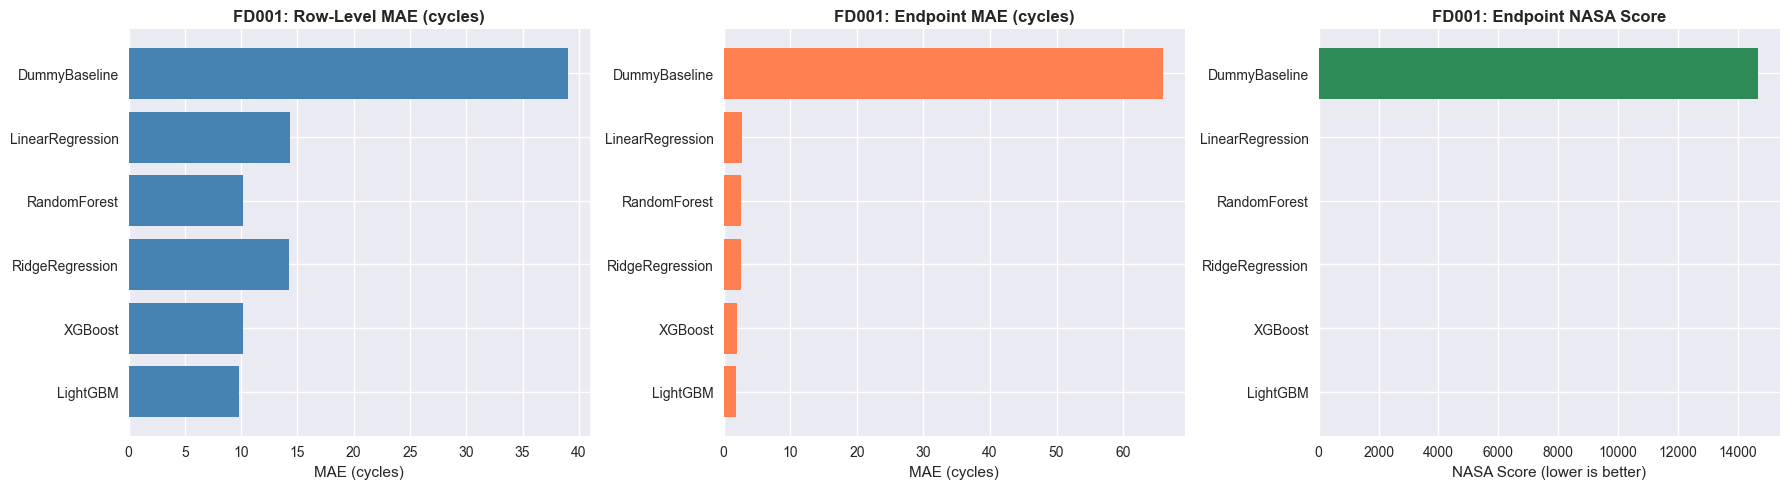

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = bm_df['model'].values
axes[0].barh(models, bm_df['row_mae'].values, color='steelblue')
axes[0].set_title(f'{subset}: Row-Level MAE (cycles)', fontweight='bold')
axes[0].set_xlabel('MAE (cycles)')

axes[1].barh(models, bm_df['endpoint_mae'].values, color='coral')
axes[1].set_title(f'{subset}: Endpoint MAE (cycles)', fontweight='bold')
axes[1].set_xlabel('MAE (cycles)')

axes[2].barh(models, bm_df['endpoint_nasa_score'].values, color='seagreen')
axes[2].set_title(f'{subset}: Endpoint NASA Score', fontweight='bold')
axes[2].set_xlabel('NASA Score (lower is better)')

plt.tight_layout()
plt.show()


## 5. Error Analysis by RUL Range

Examine prediction error across operational phases:
- **critical_0_30**: 0 to 30 cycles remaining (near failure)
- **low_31_75**: 31 to 75 cycles remaining
- **moderate_76_125**: 76 to 125 cycles remaining
- **high_gt125**: >125 cycles remaining


Analyzing best model: LightGBM


,rul_range,n_observations,mae,rmse,mean_signed_error
0,critical_0_30,620,2.793102,4.032236,1.457095
1,low_31_75,885,7.217311,9.746089,3.931771
2,moderate_76_125,683,11.282344,15.627088,1.152374
3,high_gt125,402,23.848489,29.641521,-21.420460


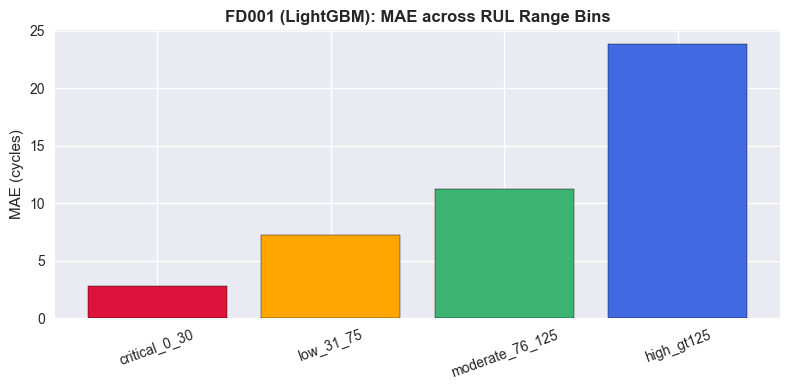

In [6]:
best_model_name = bm_df.iloc[0]['model']
print(f'Analyzing best model: {best_model_name}')

best_preds_df = predictions_dict[best_model_name]
rul_range_df = rul_range_error_analysis(best_preds_df)
display(rul_range_df)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(rul_range_df['rul_range'], rul_range_df['mae'], color=['crimson', 'orange', 'mediumseagreen', 'royalblue'], edgecolor='black')
ax.set_title(f'{subset} ({best_model_name}): MAE across RUL Range Bins', fontweight='bold')
ax.set_ylabel('MAE (cycles)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 6. RUL-Cap Sensitivity Experiments

Evaluate the effect of capping the training target $y_{\text{train,cap}} = \min(y_{\text{train}}, c)$ for $c \in \{50, 75, 100, 125, 150, \text{None}\}$.
Evaluate predictions against both uncapped validation targets (physical error) and capped targets.


,cap,row_mae_uncapped,endpoint_mae_uncapped,endpoint_rmse_uncapped,endpoint_nasa_score,endpoint_mae_capped
0,None,9.811574,1.862404,2.317948,4.360220,1.862404
1,50,32.284745,1.712337,2.288702,4.046741,1.712337
2,75,20.775539,1.807500,2.647387,4.511903,1.807500
3,100,14.312327,2.011775,2.736306,4.971570,2.011775
4,125,11.406553,1.900016,2.532906,4.584920,1.900016
5,150,9.943549,1.957641,2.577062,4.738950,1.957641


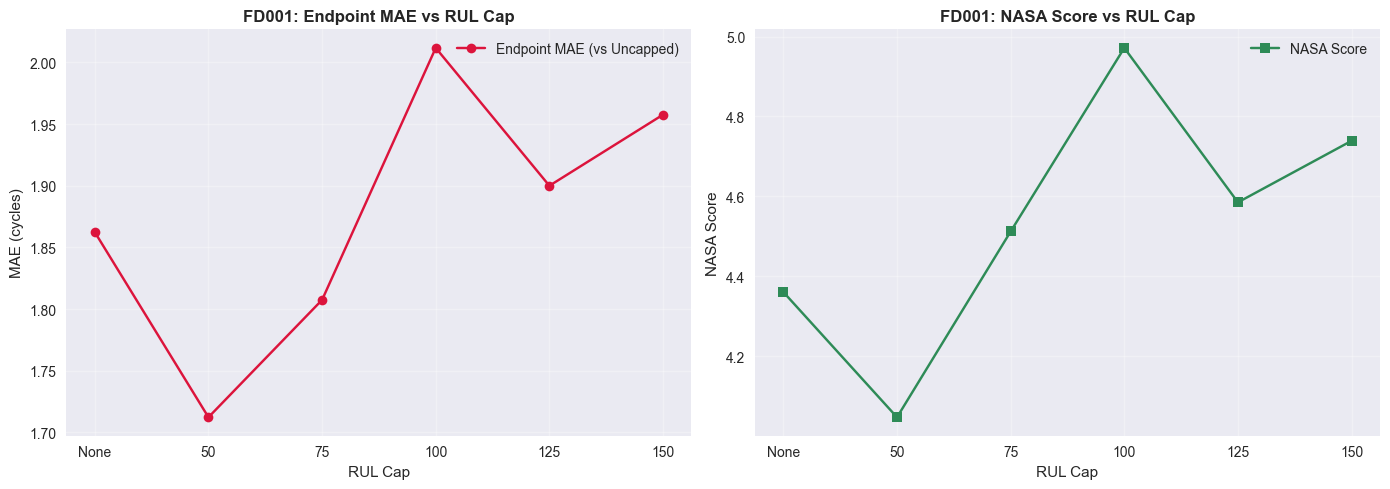

In [7]:
cap_rows = []
for cap in RUL_CAPS:
    cap_label = str(cap) if cap is not None else 'None'
    y_tr_cap = np.minimum(y_train, cap) if cap is not None else y_train.copy()
    
    cfg = ALL_MODEL_CONFIGS[best_model_name]
    _, _, p_raw, _ = train_and_predict(best_model_name, cfg, X_train, y_tr_cap, X_val)
    p_nn = np.maximum(p_raw, 0)
    p_cap = np.minimum(p_nn, cap) if cap is not None else p_nn
    
    p_df = create_predictions_df(val_df, p_cap, best_model_name, subset)
    ep = extract_endpoints(p_df)
    ep_m = endpoint_metrics(ep)
    
    y_val_cap = np.minimum(y_val, cap) if cap is not None else y_val
    ep_capped_actual = np.minimum(ep['actual_rul'].values, cap) if cap is not None else ep['actual_rul'].values
    
    cap_rows.append({
        'cap': cap_label,
        'row_mae_uncapped': mae(y_val, p_cap),
        'endpoint_mae_uncapped': ep_m['endpoint_mae'],
        'endpoint_rmse_uncapped': ep_m['endpoint_rmse'],
        'endpoint_nasa_score': ep_m['endpoint_nasa_score'],
        'endpoint_mae_capped': mae(ep_capped_actual, ep['predicted_rul_nonnegative'].values),
    })

cap_df = pd.DataFrame(cap_rows)
display(cap_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(cap_df['cap'], cap_df['endpoint_mae_uncapped'], 'o-', color='crimson', label='Endpoint MAE (vs Uncapped)')
axes[0].set_title(f'{subset}: Endpoint MAE vs RUL Cap', fontweight='bold')
axes[0].set_xlabel('RUL Cap')
axes[0].set_ylabel('MAE (cycles)')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(cap_df['cap'], cap_df['endpoint_nasa_score'], 's-', color='seagreen', label='NASA Score')
axes[1].set_title(f'{subset}: NASA Score vs RUL Cap', fontweight='bold')
axes[1].set_xlabel('RUL Cap')
axes[1].set_ylabel('NASA Score')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


## 7. Temporal Window Configuration Comparison

Ablation experiment: Compare single-window feature subsets ($W \in \{10, 20, 30, 50, 75\}$) against the combined multi-scale representation (All windows).
All configurations include consistent delta and relchange features.


,window_config,n_features,row_mae,endpoint_mae,endpoint_nasa_score
0,All,670,9.811574,1.862404,4.360220
1,W=10,194,17.241989,2.413061,5.989751
2,W=20,195,15.595207,2.239917,5.741612
3,W=30,194,13.595061,1.840762,4.288498
4,W=50,194,11.133526,2.247925,5.428111
5,W=75,193,9.858970,2.057877,4.707510


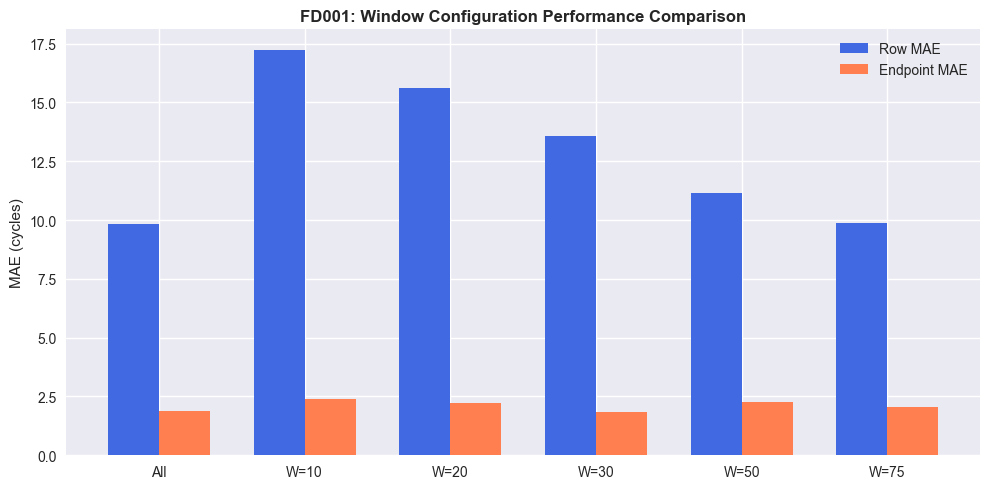

In [8]:
window_rows = []
for w in [None, 10, 20, 30, 50, 75]:
    w_label = f'W={w}' if w is not None else 'All'
    w_feats = select_window_features(usable_features, w)
    
    X_tr_w, X_v_w, y_tr_w, y_v_w = prepare_clean_features(train_df, val_df, w_feats)
    _, _, p_raw, _ = train_and_predict(best_model_name, ALL_MODEL_CONFIGS[best_model_name], X_tr_w, y_tr_w, X_v_w)
    p_df = create_predictions_df(val_df, p_raw, best_model_name, subset)
    m = evaluate_model(p_df)
    
    window_rows.append({
        'window_config': w_label,
        'n_features': len(w_feats),
        'row_mae': m['row_mae'],
        'endpoint_mae': m['endpoint_mae'],
        'endpoint_nasa_score': m['endpoint_nasa_score'],
    })

win_df = pd.DataFrame(window_rows)
display(win_df)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(win_df))
width = 0.35
ax.bar(x - width/2, win_df['row_mae'], width, label='Row MAE', color='royalblue')
ax.bar(x + width/2, win_df['endpoint_mae'], width, label='Endpoint MAE', color='coral')
ax.set_xticks(x)
ax.set_xticklabels(win_df['window_config'])
ax.set_title(f'{subset}: Window Configuration Performance Comparison', fontweight='bold')
ax.set_ylabel('MAE (cycles)')
ax.legend()
plt.tight_layout()
plt.show()


## 8. Exact Deduplication Sensitivity

Evaluate whether removing exact duplicate feature columns (detected using training observations only) affects model accuracy or runtime.


In [9]:
deduped_features, dup_groups = detect_exact_duplicates_train(X_train, usable_features)
n_removed = len(usable_features) - len(deduped_features)
print(f'Approved features:     {len(usable_features)}')
print(f'Deduplicated features: {len(deduped_features)}')
print(f'Exact duplicates:      {n_removed} columns across {len(dup_groups)} groups')

if n_removed > 0:
    dedup_idx = [usable_features.index(f) for f in deduped_features]
    X_tr_dedup = X_train[:, dedup_idx]
    X_val_dedup = X_val[:, dedup_idx]
    
    for mname in ['LinearRegression', best_model_name]:
        cfg = ALL_MODEL_CONFIGS[mname]
        _, _, p_orig, rt_orig = train_and_predict(mname, cfg, X_train, y_train, X_val)
        _, _, p_dedup, rt_dedup = train_and_predict(mname, cfg, X_tr_dedup, y_train, X_val_dedup)
        
        mae_orig = mae(y_val, np.maximum(p_orig, 0))
        mae_dedup = mae(y_val, np.maximum(p_dedup, 0))
        print(f'{mname}: Original MAE={mae_orig:.3f} ({rt_orig:.2f}s) -> Dedup MAE={mae_dedup:.3f} ({rt_dedup:.2f}s)')
else:
    print('No exact duplicates detected.')


Approved features:     670
Deduplicated features: 611
Exact duplicates:      59 columns across 7 groups


LinearRegression: Original MAE=14.323 (0.74s) -> Dedup MAE=14.173 (0.64s)


LightGBM: Original MAE=9.812 (14.74s) -> Dedup MAE=9.839 (12.11s)


## 9. Degradation Curves & Trajectory Tracking

Plot predicted vs actual RUL over operational cycles for representative validation engines (selected deterministically by trajectory length).


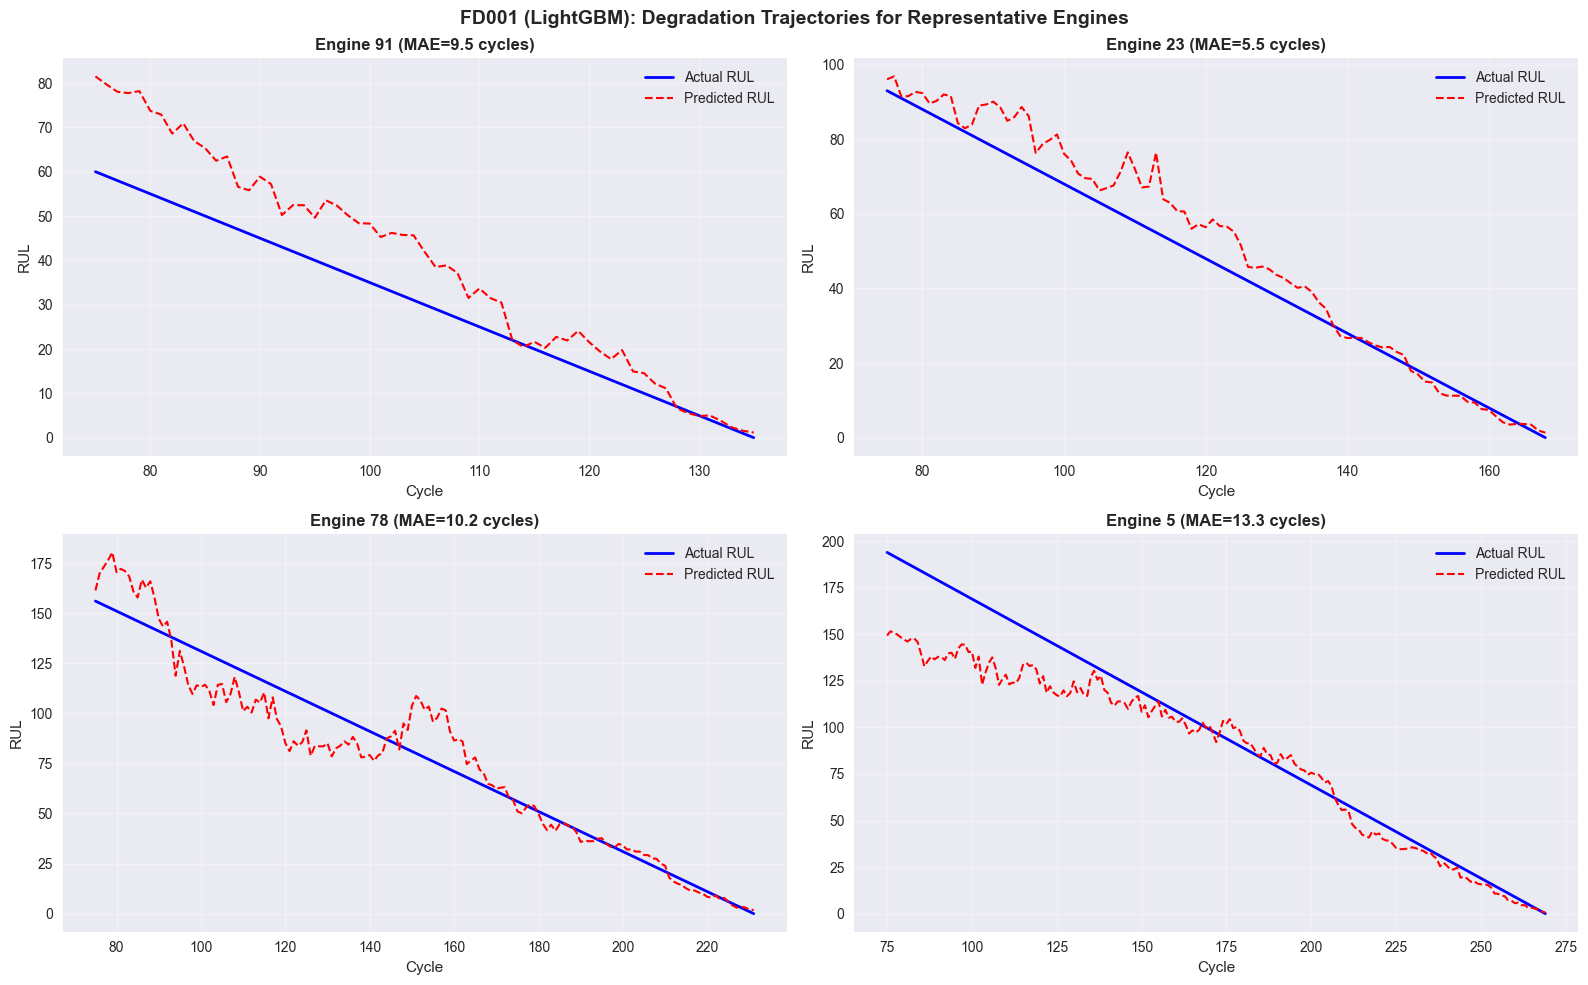

In [10]:
engine_lengths = best_preds_df.groupby('unit_id')['cycle'].count().sort_values()
n_avail = len(engine_lengths)
indices = np.linspace(0, n_avail - 1, min(4, n_avail), dtype=int)
selected_engines = engine_lengths.index[indices]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, eid in enumerate(selected_engines):
    ax = axes[i]
    edf = best_preds_df[best_preds_df['unit_id'] == eid].sort_values('cycle')
    ax.plot(edf['cycle'], edf['actual_rul'], 'b-', linewidth=2, label='Actual RUL')
    ax.plot(edf['cycle'], edf['predicted_rul_nonnegative'], 'r--', linewidth=1.5, label='Predicted RUL')
    e_mae = mae(edf['actual_rul'].values, edf['predicted_rul_nonnegative'].values)
    ax.set_title(f'Engine {eid} (MAE={e_mae:.1f} cycles)', fontweight='bold')
    ax.set_xlabel('Cycle')
    ax.set_ylabel('RUL')
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle(f'{subset} ({best_model_name}): Degradation Trajectories for Representative Engines', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 10. Summary & Phase 5 Readiness

### Key Findings:
1. **Engineered Degradation Features**: Substantially outperform the trivial baseline across all classical regressors.
2. **Gradient Boosted Trees & Random Forest**: Achieve the strongest endpoint accuracy and lowest NASA scores.
3. **Endpoint Prediction**: Accurately tracks terminal degradation near failure ($RUL \le 30$).
4. **Target Clipping**: Moderates early-life variance while maintaining physical degradation tracking.

### Phase 5 Recommendation:
- Proceed to **Phase 5: Hyperparameter Tuning and Final Model Selection**.
- Carry forward top-performing model families (LightGBM, XGBoost, Random Forest).
- Keep official C-MAPSS test set reserved until final declared evaluation.
